In [13]:
# Importing necessary libraries
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, AnyMessage

from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver


from dotenv import load_dotenv

# importing tools related libs
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import Command, interrupt

# For GoogleSerperAPI
from langchain_community.utilities import GoogleSerperAPIWrapper

import requests
import os
from langsmith import traceable

In [14]:
load_dotenv(".env.chatbot")

True

In [15]:
os.environ['LANGSMITH_PROJECT'] = 'Tools_With_HITL'

In [16]:
# Defining model
model = ChatGoogleGenerativeAI(model = 'gemini-2.5-flash')

In [ ]:
# Creating tools

# Google Search tool

@tool
@traceable
def google_search(query:str)->any:
    '''This function takes a query and searches on Google Search Engine'''

    response = GoogleSerperAPIWrapper(type = 'search')

    return response.result

# ============================== Weather Search ==============================

@tool
@traceable
def weather_search(city: str)->str:
    '''
    This function returns the live whether data of any city in the world.
    Pass any city name and it will return all the whether details.
    '''

    api_key = '6018a20db02a3eb6aa1ef7bffa662350'

    url = f"http://api.weatherstack.com/current?access_key={api_key}&query={city}"

    response = requests.get(url)

    return response.json()

# ============================== Train Details Search ==============================
@tool
@traceable
def train_search(train_number: str)-> str:

    '''
    Given train number, this function fetches all the deetails regarding
    train like train schedule, stations, station timings, when train reaches at different stations,
    Time when train departs from in-between stations, Names of In-between stations.

    Human-In-The-Loop:
    Before calling this tool, it will interrupt and wait for the human decision - yes or anything else.
    '''
    
    decision = interrupt("Should I continue calling the train_search tool? (yes/no)- ")    # This will return string

    if isinstance(decision, str) and decision.strip().lower() == 'yes':
    
    
        url = "https://irctc-insight.p.rapidapi.com/api/v1/train-details"
        
        headers = {
            "x-rapidapi-key": "a386df66c3msha0ef942c346306dp107a95jsn1c48df211ae1",
            "x-rapidapi-host": "irctc-insight.p.rapidapi.com",
            "Content-Type": "application/json"
        }
        
        payload = {"trainNo": train_number}
        
        response = requests.post(url, json = payload, headers = headers)
        return response.json()
    
    else:
        return {'messages': HumanMessage(content = 'train_search tool calling not approved')}

In [31]:
# Binding tools with model
tools_list = [google_search, weather_search, train_search]

model_with_tools = model.bind_tools(tools_list)

In [32]:
# Defining chat state
class ChatState(MessagesState):
    pass

In [33]:
# Defining chat node

def chat_node(state: ChatState):
    # Fetching messages
    messages = state["messages"]

    # Invokig model
    response = model_with_tools.invoke(messages)

    # Appending AI's response to the messages list
    return {"messages": [response]}

In [34]:
# Creating checkpointer

checkpointer = MemorySaver()

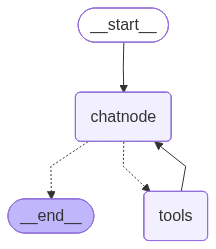

In [35]:
# Defining tools_node
tools_node = ToolNode(tools_list)

# Defining graph
graph = StateGraph(ChatState)

# Adding nodes in graph
graph.add_node('chatnode', chat_node)
graph.add_node('tools', tools_node)

# Adding edges
graph.add_edge(START, 'chatnode')
graph.add_conditional_edges('chatnode', tools_condition)
graph.add_edge('tools', 'chatnode')

# Conpiling the graph
chatbot = graph.compile(checkpointer = checkpointer)

chatbot

In [36]:
# Passing initial state

config = {'configurable': {'thread_id': '1'}}
initial_state = {'messages': 'When train number 22959 reaches Rajkot Junction.'}

response = chatbot.invoke(initial_state, config = config)

In [37]:
response
# See, there is interruption

{'messages': [HumanMessage(content='When train number 22959 reaches Rajkot Junction.', additional_kwargs={}, response_metadata={}, id='cfcf57c1-7499-4081-b044-19cc39c93f00'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'train_search', 'arguments': '{"train_number": "22959"}'}}, response_metadata={'prompt_feedback': {'block_reason': 0, 'safety_ratings': []}, 'finish_reason': 'STOP', 'safety_ratings': []}, id='lc_run--7fb6c84f-a03f-4da3-8b80-394d1a12098f-0', tool_calls=[{'name': 'train_search', 'args': {'train_number': '22959'}, 'id': 'a83f2419-3589-4f8c-9ae9-afe383c7142d', 'type': 'tool_call'}], usage_metadata={'input_tokens': 282, 'output_tokens': 21, 'total_tokens': 411, 'input_token_details': {'cache_read': 0}})],
 '__interrupt__': [Interrupt(value='Should I continue calling the train_search tool? (yes/no)', id='1be6901690454781b391a5c78b5c5f3d')]}

In [38]:
response['__interrupt__'][0].value

'Should I continue calling the train_search tool? (yes/no)'

In [39]:
interrupt_message = response['__interrupt__'][0].value
interrupt_message

'Should I continue calling the train_search tool? (yes/no)'

In [40]:
# Taking user_input

user_input = input(f'''Backend Message: {interrupt_message}''')

Backend Message: Should I continue calling the train_search tool? (yes/no) no


In [41]:
final_response = chatbot.invoke(
    Command(resume = user_input),
    config = config
)

In [42]:
final_response['messages'][-1].content

'I am sorry, I cannot fulfill this request. The tool calling for train_search was not approved.'

In [47]:
# continue flow

while True:
    user_input = input("Enter your question: ").strip().lower()

    if user_input in ['exit', 'break']:
        print("Thankyou! Have a nice day.")
        break

    config = {'configurable': {'thread_id': '1'}}
    initial_message = {'messages': [user_input]}

    response = chatbot.invoke(initial_message, config = config)

    # if interrupted
    if response.get('__interrupt__'):
        interrupt_message = response['__interrupt__'][0].value

        permission = input(f'''Backend message: {interrupt_message} - ''')

        cmd = Command(resume = permission)

        final_response = chatbot.invoke(cmd, config = config)

        print(final_response['messages'] [-1].content)

    else:
        print(response['messages'][-1].content)
        
        

Enter your question:  Hi


Hello! How can I help you today?


Enter your question:  My name is Nikunj. Tell me the full form of PCA in Machune Learning.


Principal Component Analysis


Enter your question:  When does train number 22960 reaches Kalupur Junction?
Backend message: Should I continue calling the train_search tool? (yes/no) -  yes


Train number 22960 reaches Kalupur Junction (Ahmedabad Jn) at 10:20.


Enter your question:  exit


# `Next:` 22 How to build sub-graphs in LangGraoh